In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [2]:
data = load_wine(as_frame=True)

df = data.data  

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
print("Dataset shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())

print("\nFeature names:")
print(df.columns.tolist())

df.describe()

Dataset shape: (178, 13)

Missing values: 0

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (178, 13)


| Hyperparameter     | Meaning                                      | Example           |
| ------------------ | -------------------------------------------- | ----------------- |
| `n_clusters=3`     | Number of clusters to form                   | `2`, `3`, `4`     |
| `init="k-means++"` | Strategy for choosing initial centroids      | `"random"`        |
| `n_init=10`        | Number of initializations attempted          | `10`, `20`        |
| `max_iter=300`     | Maximum iterations per initialization        | `100`, `300`      |
| `tol=0.0001`       | Relative tolerance used to check convergence | `0.001`, `0.0001` |
| `random_state=42`  | Controls randomization for reproducibility   | `42`              |


In [5]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    max_iter=300,
    tol=0.0001,
    random_state=42
)

kmeans.fit(X_scaled)

print("Clustering completed!")

Clustering completed!


#### **`kmeans.labels_` contains the cluster assignments for the samples used during fitting.**

In [6]:
labels = kmeans.labels_ 

print("First 20 cluster assignments:")
print(labels[:20])

print("\nCluster sizes:")
print(pd.Series(labels).value_counts().sort_index())

First 20 cluster assignments:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]

Cluster sizes:
0    65
1    51
2    62
Name: count, dtype: int64


| Metric                      | Better result, generally    |
| --------------------------- | --------------------------- |
| **Inertia**                 | Lower                       |
| **Silhouette Score**        | Higher; ranges from −1 to 1 |
| **Davies-Bouldin Score**    | Lower                       |
| **Calinski-Harabasz Score** | Higher                      |


##### **1. Inertia measures the sum of squared distances between each observation and its assigned centroid.**
##### **2. The silhouette score measures how well an observation fits its assigned cluster compared with the nearest alternative cluster.**


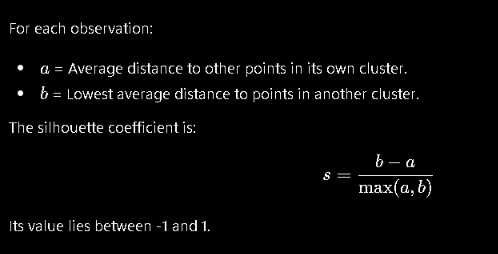

#### **3. Davies-Bouldin Score**-**This metric compares within-cluster spread with separation between clusters or The Davies-Bouldin score summarizes these relationships across clusters.**

### **4. Calinski-Harabasz Score**

#### **This metric compares:**
#### 1. How separated the cluster centers are.
#### 2. How spread out the observations are within clusters.

In [7]:
print("Inertia:", kmeans.inertia_) # Lower inertia means the observations are closer to their assigned centroids.

print(
    "Silhouette Score:",
    silhouette_score(X_scaled, labels)
)

print(
    "Davies-Bouldin Score:",
    davies_bouldin_score(X_scaled, labels)
)

print(
    "Calinski-Harabasz Score:",
    calinski_harabasz_score(X_scaled, labels)
)

Inertia: 1277.928488844642
Silhouette Score: 0.2848589191898987
Davies-Bouldin Score: 1.3891879777181646
Calinski-Harabasz Score: 70.9400080031512


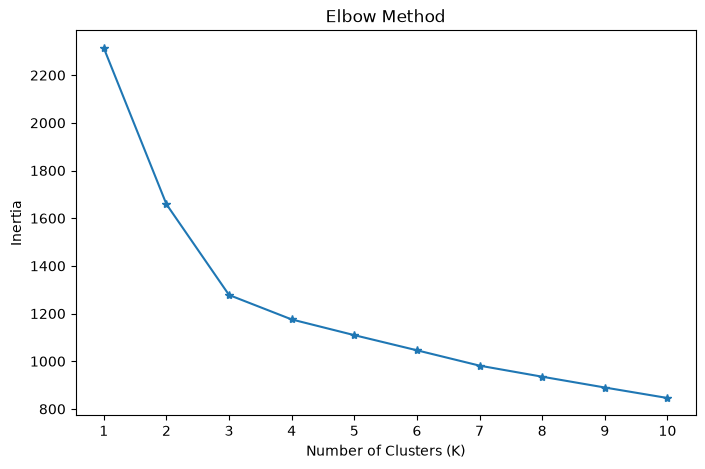

In [8]:
inertias = []

k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="*")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.show()

In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_pca.shape)

Original dimensions: (178, 13)
Reduced dimensions: (178, 2)


In [10]:
print(X_pca)
print("------------------")
print(X_scaled)

[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]
 [ 3.05025392  2.12240111]
 [ 2.44908967  1.17485013]
 [ 2.05943687  1.60896307]
 [ 2.5108743   0.91807096]
 [ 2.75362819  0.78943767]
 [ 3.47973668  1.30233324]
 [ 1.7547529   0.61197723]
 [ 2.11346234  0.67570634]
 [ 3.45815682  1.13062988]
 [ 4.31278391  2.09597558]
 [ 2.3051882   1.66255173]
 [ 2.17195527  2.32730534]
 [ 1.89897118  1.63136888]
 [ 3.54198508  2.51834367]
 [ 2.0845222   1.06113799]
 [ 3.12440254  0.78689711]
 [ 1.08657007  0.24174355]
 [ 2.53522408 -0.09184062]
 [ 1.64498834 -0.51627893]
 [ 1.76157587 -0.31714893]
 [ 0.9900791   0.94066734]
 [ 1.77527763  0.68617513]
 [ 1.23542396 -0.08980704]
 [ 2.18840633  0.68956962]
 [ 2.25610898  0.19146194]
 [ 2.50022003  1.24083383]
 [ 2.67741105  1.47187365]
 [ 1.62857912  0.05270445]
 [ 1.90269086  1.63306043]
 [ 1.41038853  0.69793432]
 [ 1.90382623  0.17671095]
 [ 1.38486223  0.65863985]
 

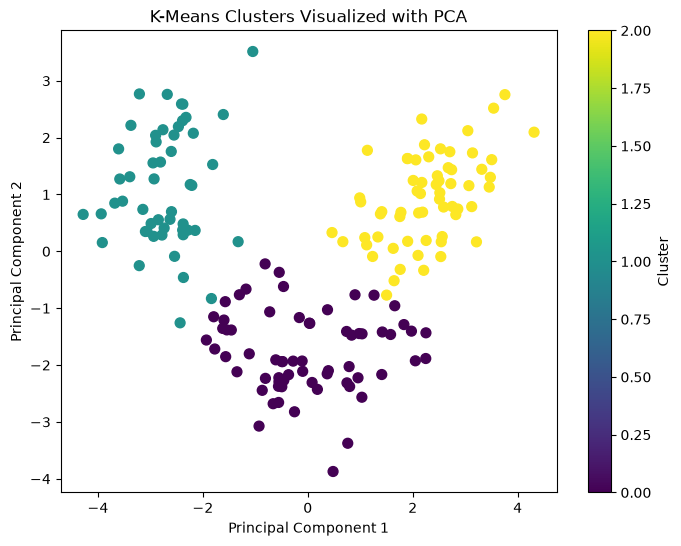

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],  # PC1
    X_pca[:, 1],  # PC2
    c=labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized with PCA")
plt.colorbar(label="Cluster")
plt.show()

In [12]:
print("PC1 variance:", pca.explained_variance_ratio_[0]) # explained_variance_ratio_[0] → Percentage of variance captured by PC1.
print("PC2 variance:", pca.explained_variance_ratio_[1])

print("Total variance preserved:",
      pca.explained_variance_ratio_.sum())

PC1 variance: 0.3619884809992632
PC2 variance: 0.19207490257008938
Total variance preserved: 0.5540633835693526


# **Hierarchical Clustering**

In [13]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

| Parameter            | Meaning                                                             |
| -------------------- | ------------------------------------------------------------------- |
| `linkage="ward"`     | Merge clusters to minimize the increase in within-cluster variance. |


#### **Important:** Ward linkage requires Euclidean distance, so don't combine it with other metrics such as Manhattan distance.

In [14]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    metric="euclidean",
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [15]:
print("Cluster labels:", np.unique(hierarchical_labels))
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Cluster labels: [0 1 2]
0    58
1    56
2    64
Name: count, dtype: int64


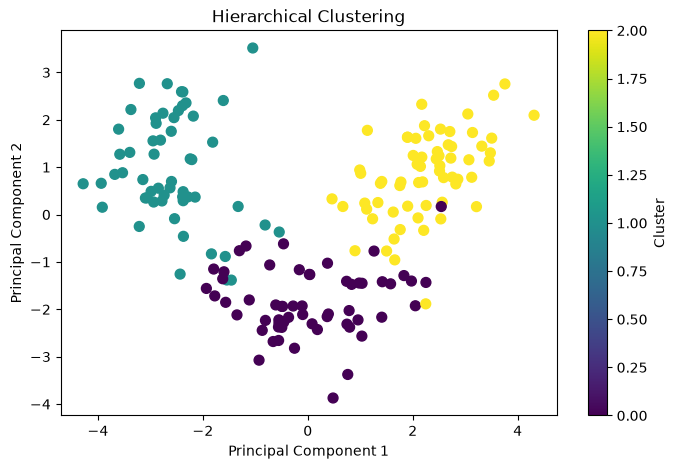

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Clustering")
plt.colorbar(label="Cluster")
plt.show()

In [27]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Hierarchical Clustering Evaluation")

print("Silhouette Score:",
      silhouette_score(X_scaled, hierarchical_labels))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, hierarchical_labels))

print("Calinski-Harabasz Index:",
      calinski_harabasz_score(X_scaled, hierarchical_labels))

Hierarchical Clustering Evaluation
Silhouette Score: 0.2774439826952266
Davies-Bouldin Index: 1.4185919431857326
Calinski-Harabasz Index: 67.6474675044098


# **DBSCAN**

| Parameter            | Meaning                                                                         |
| -------------------- | ------------------------------------------------------------------------------- |
| `eps=1.5`            | Maximum distance for samples to be considered neighbors.                        |
| `min_samples=5`      | Minimum neighborhood sample count for a core point, including the point itself. |


### **Important:** eps=1.5 is only a starting value, not a guaranteed good setting for this dataset. DBSCAN may produce one cluster, several clusters, or mostly noise. We'll inspect its output and adjust eps if necessary.



In [16]:
dbscan_model = DBSCAN(
    eps=1.5,
    min_samples=5,
    metric="euclidean"
)

dbscan_labels = dbscan_model.fit_predict(X_scaled)

In [17]:
print("Cluster labels:", np.unique(dbscan_labels))
print(pd.Series(dbscan_labels).value_counts().sort_index())

Cluster labels: [-1]
-1    178
Name: count, dtype: int64


In [30]:
import numpy as np
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("DBSCAN Evaluation")

mask = dbscan_labels != -1

X_dbscan = X_scaled[mask]
labels_dbscan = dbscan_labels[mask]

print("Number of clusters:",
      len(set(labels_dbscan)))

print("Number of noise points:",
      np.sum(dbscan_labels == -1))

if 2 <= len(np.unique(labels_dbscan)) < len(labels_dbscan):

    print("Silhouette Score:",
          silhouette_score(X_dbscan, labels_dbscan))

    print("Davies-Bouldin Index:",
          davies_bouldin_score(X_dbscan, labels_dbscan))

    print("Calinski-Harabasz Index:",
          calinski_harabasz_score(X_dbscan, labels_dbscan))

else:
    print("Cannot calculate the metrics: insufficient clusters or samples.")

DBSCAN Evaluation
Number of clusters: 0
Number of noise points: 178
Cannot calculate the metrics: insufficient clusters or samples.


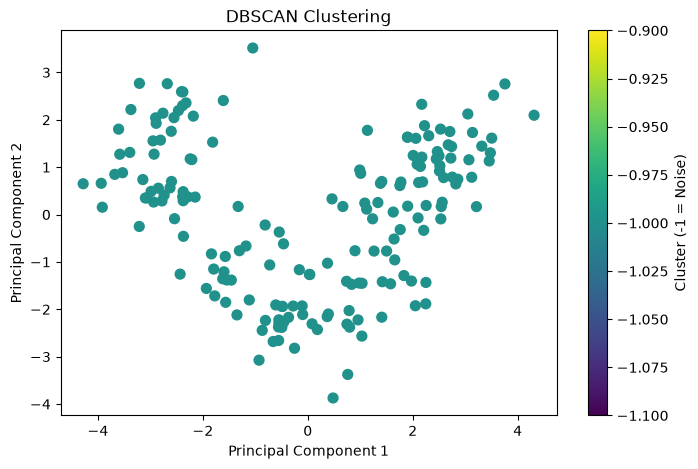

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

# **Gaussian Mixture Model (GMM)**

| Parameter                | Meaning                                                        |
| ------------------------ | -------------------------------------------------------------- |
| `n_components=3`         | Model three Gaussian mixture components.                       |
| `covariance_type="full"` | Each component can have its own full covariance matrix.        |
| `n_init=5`               | Try five initializations and retain the best-fitting solution. |
| `random_state=42`        | Make initialization reproducible.                              |


In [18]:
gmm_model = GaussianMixture(
    n_components=3,
    covariance_type="full",
    n_init=5,
    random_state=42
)

gmm_model.fit(X_scaled)

gmm_labels = gmm_model.predict(X_scaled)

In [20]:
print("Cluster labels:", np.unique(gmm_labels))
print(pd.Series(gmm_labels).value_counts().sort_index())

Cluster labels: [0 1 2]
0    63
1    64
2    51
Name: count, dtype: int64


#### **Unlike K-Means, GMM models the data using probability distributions.**

In [21]:
gmm_probabilities = gmm_model.predict_proba(X_scaled)

print("Probability shape:", gmm_probabilities.shape)
print(gmm_probabilities[:5])

Probability shape: (178, 3)
[[1.00000000e+00 4.34822122e-18 5.29201393e-51]
 [9.99999999e-01 1.26017317e-09 1.87286238e-45]
 [9.99999999e-01 1.06090478e-09 1.04420861e-55]
 [1.00000000e+00 1.41364048e-23 3.22602159e-87]
 [9.99828776e-01 1.71223865e-04 1.21346528e-23]]


In [28]:
print("Gaussian Mixture Model Evaluation")

print("Silhouette Score:",
      silhouette_score(X_scaled, gmm_labels))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, gmm_labels))

print("Calinski-Harabasz Index:",
      calinski_harabasz_score(X_scaled, gmm_labels))

print("AIC:", gmm_model.aic(X_scaled))

print("BIC:", gmm_model.bic(X_scaled))

Gaussian Mixture Model Evaluation
Silhouette Score: 0.2844212860533542
Davies-Bouldin Index: 1.3938008647586722
Calinski-Harabasz Index: 70.68777673224997
AIC: 4807.205086385826
BIC: 5806.2851211775405


In [31]:
aic = gmm_model.aic(X_scaled)
bic = gmm_model.bic(X_scaled)

print("AIC:", aic)
print("BIC:", bic)

AIC: 4807.205086385826
BIC: 5806.2851211775405


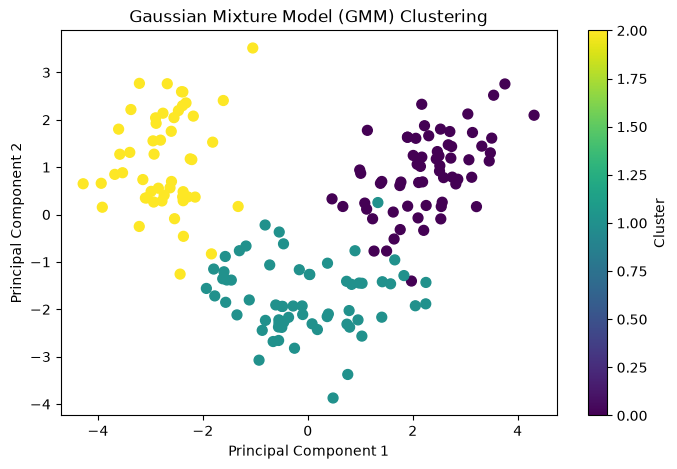

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Gaussian Mixture Model (GMM) Clustering")
plt.colorbar(label="Cluster")
plt.show()

In [22]:
results = {
    "KMeans": kmeans.labels_,
    "Hierarchical": hierarchical_labels,
    "DBSCAN": dbscan_labels,
    "GMM": gmm_labels
}

for name, labels in results.items():
    print(f"\n{name}")
    print(pd.Series(labels).value_counts().sort_index())


KMeans
0    65
1    51
2    62
Name: count, dtype: int64

Hierarchical
0    58
1    56
2    64
Name: count, dtype: int64

DBSCAN
-1    178
Name: count, dtype: int64

GMM
0    63
1    64
2    51
Name: count, dtype: int64
